In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler as ss
from scipy.stats import pearsonr as prs

In [2]:
try:
    df = pd.read_csv('heart.csv')
except Exception as e:
    print(e)
else:
    print('Imported')

Imported


# EDA

In [3]:
print(f'Shape: {df.shape}\nTotal Rows: {df.shape[0]}\nTotal Cols: {df.shape[1]}')

Shape: (918, 12)
Total Rows: 918
Total Cols: 12


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [5]:
display(df.sample(15))

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
282,51,F,NAP,130,220,0,Normal,160,Y,2.0,Up,0
425,60,M,ATA,160,267,1,ST,157,N,0.5,Flat,1
273,55,M,NAP,120,220,0,LVH,134,N,0.0,Up,0
889,59,M,TA,134,204,0,Normal,162,N,0.8,Up,1
199,57,F,TA,130,308,0,Normal,98,N,1.0,Flat,0
709,52,M,ASY,125,212,0,Normal,168,N,1.0,Up,1
857,53,F,ASY,130,264,0,LVH,143,N,0.4,Flat,0
788,68,F,NAP,120,211,0,LVH,115,N,1.5,Flat,0
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
667,65,F,NAP,140,417,1,LVH,157,N,0.8,Up,0


In [6]:
df.columns.to_list()

['Age',
 'Sex',
 'ChestPainType',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'RestingECG',
 'MaxHR',
 'ExerciseAngina',
 'Oldpeak',
 'ST_Slope',
 'HeartDisease']

### Converting all the column names into lower case

In [7]:
df.columns = df.columns.str.lower()
df.columns.to_list()

['age',
 'sex',
 'chestpaintype',
 'restingbp',
 'cholesterol',
 'fastingbs',
 'restingecg',
 'maxhr',
 'exerciseangina',
 'oldpeak',
 'st_slope',
 'heartdisease']

### Separating Numerical and Categorical Columns

In [8]:
num_cols = ['age', 'restingbp', 'cholesterol', 'maxhr', 'oldpeak']
cat_cols = [col for col in df.columns if col not in num_cols]

print(f'Numerical Columns: {', '.join(num_cols)}')
print(f'Categorical Columns: {', '.join(cat_cols)}')

Numerical Columns: age, restingbp, cholesterol, maxhr, oldpeak
Categorical Columns: sex, chestpaintype, fastingbs, restingecg, exerciseangina, st_slope, heartdisease


### Calculating Missing Values

In [9]:
df.isna().sum()

age               0
sex               0
chestpaintype     0
restingbp         0
cholesterol       0
fastingbs         0
restingecg        0
maxhr             0
exerciseangina    0
oldpeak           0
st_slope          0
heartdisease      0
dtype: int64

### Calculating Null values


In [10]:
df.isnull().sum()

age               0
sex               0
chestpaintype     0
restingbp         0
cholesterol       0
fastingbs         0
restingecg        0
maxhr             0
exerciseangina    0
oldpeak           0
st_slope          0
heartdisease      0
dtype: int64

### Calculating duplicate values

In [11]:
df.duplicated().sum()

np.int64(0)

### Creating Histogram for Numerical Data

In [12]:
def create_hist_plot(var, row, col, loc):
    plt.subplot(row, col, loc)
    sns.histplot(x=df[var], kde=True)
    plt.tight_layout()

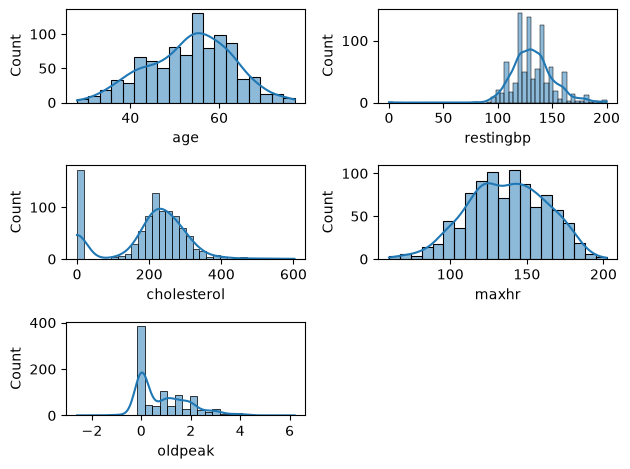

In [13]:
for i, col in enumerate(num_cols):
    create_hist_plot(col, 3, 2, i+1)

In [14]:
df['cholesterol'].agg(['min', 'max'])

min      0
max    603
Name: cholesterol, dtype: int64

In [15]:
df['restingbp'].agg(['min', 'max'])

min      0
max    200
Name: restingbp, dtype: int64

In [16]:
print(f"People having 0 Cholesterol BP: {(df['cholesterol']==0).sum()}")
print(f"People having 0 Resting BP: {(df['restingbp']==0).sum()}")

People having 0 Cholesterol BP: 172
People having 0 Resting BP: 1


### Observation:
```
    01. A person can not have 0 cholesterol
    02. A person can not have 0 resting bp
```

### Replacing the 0 value with the mean

In [17]:
chol_mean = df.loc[df['cholesterol']!=0, 'cholesterol'].mean().round(2)
df['cholesterol'] = df['cholesterol'].replace(0, chol_mean)
(df['cholesterol']==0).sum()

np.int64(0)

In [18]:
restbp_mean = df.loc[df['restingbp']!=0, 'restingbp'].mean().round(2)
df['restingbp'] = df['restingbp'].replace(0, restbp_mean)
(df['restingbp']==0).sum()

np.int64(0)

```Now no person has 0 cholesterol and resting BP```

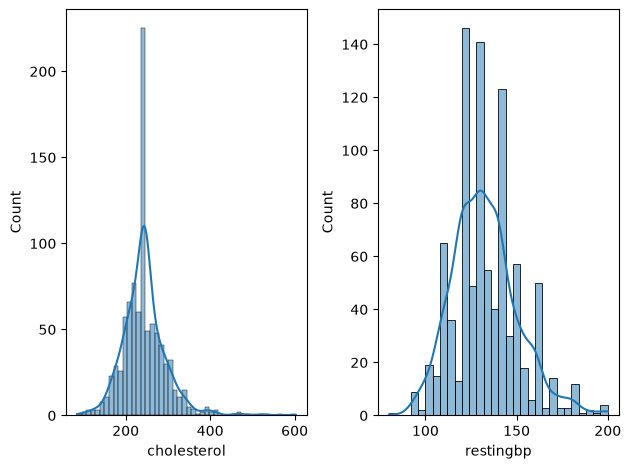

In [19]:
create_hist_plot('cholesterol', 1, 2, 1)
create_hist_plot('restingbp', 1, 2, 2)

### Checking the Categorical Data

```Heartdisease Rate based on Sex and Age Group```

In [20]:
df['age'].agg(['min', 'max'])

min    28
max    77
Name: age, dtype: int64

``` Min age: 28, Max age: 77```

In [21]:
df['age_group'] = pd.cut(
    df['age'],
    bins = [20, 30, 40, 50, 60, 70, 80],
    labels = ['20-30', '30-40', '40-50', '50-60', '60-70', '70-80']
)

```Created Age Group```
```
20-30
30-40
40-50
50-60
60-70
70-80
```

In [22]:
age_group_df = df.groupby(['age_group', 'sex'])['heartdisease'].mean().mul(100).round(2).reset_index(name='heartdisease_rate')
age_group_df

,age_group,sex,heartdisease_rate
0,20-30,F,0.00
1,20-30,M,0.00
2,30-40,F,21.05
3,30-40,M,40.58
4,40-50,F,12.07
5,40-50,M,52.12
6,50-60,F,28.57
7,50-60,M,64.95
8,60-70,F,46.15
9,60-70,M,80.38


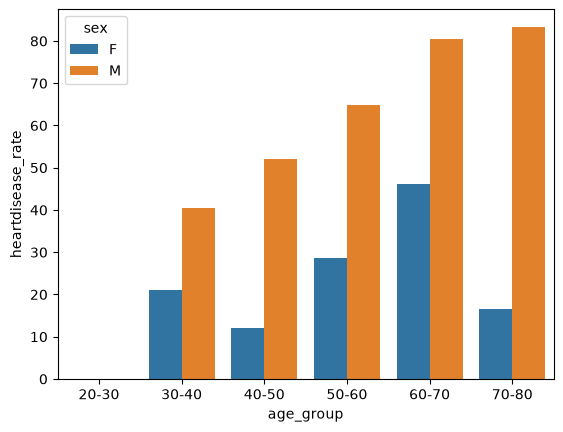

In [23]:
sns.barplot(
    data=age_group_df,
    x='age_group',
    y='heartdisease_rate',
    hue='sex'
)

plt.show()

```Observation: Male have higher heartdisease rate compared to Female```

In [24]:
df['chestpaintype'].unique()

<ArrowStringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str

In [25]:
chestpaintype_df = df.groupby('chestpaintype')['heartdisease'].mean().mul(100).round(2).reset_index(name='heardisease_rate')
chestpaintype_df

,chestpaintype,heardisease_rate
0,ASY,79.03
1,ATA,13.87
2,NAP,35.47
3,TA,43.48


<Axes: xlabel='chestpaintype', ylabel='heardisease_rate'>

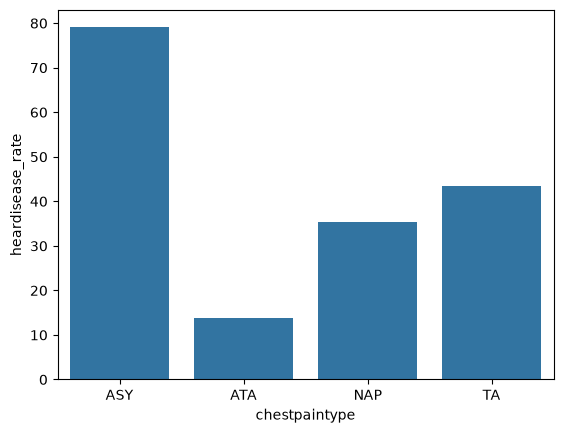

In [26]:
sns.barplot(data=chestpaintype_df, x='chestpaintype', y='heardisease_rate')

```Observation: ASY has severe heartdisease rate```

```Breaking down the fastibg BS matter into more details```

In [27]:
fastingbs_df = df.groupby(['fastingbs'])['heartdisease'].mean().mul(100).round(2).reset_index(name='heartdisease_rate')
fastingbs_df

,fastingbs,heartdisease_rate
0,0,48.01
1,1,79.44


<Axes: xlabel='fastingbs', ylabel='heartdisease_rate'>

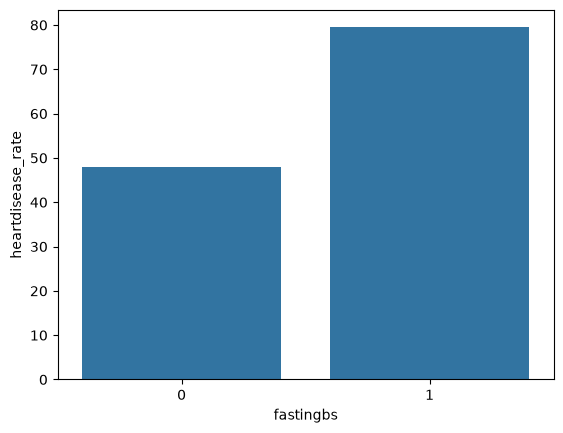

In [28]:
sns.barplot(data=fastingbs_df, x='fastingbs', y='heartdisease_rate')

```Observation```
```
    fastingBS: 0 -> Normal Range (Lower risk)
    fastingBS: 1 -> Abnormal Range (Higher Risk)
```

In [29]:
df['restingecg'].unique()

<ArrowStringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str

In [30]:
restingecg_df = df.groupby(['restingecg'])['heartdisease'].mean().mul(100).round(2).reset_index(name='heartdisease_rate')
restingecg_df

,restingecg,heartdisease_rate
0,LVH,56.38
1,Normal,51.63
2,ST,65.73


<Axes: xlabel='restingecg', ylabel='heartdisease_rate'>

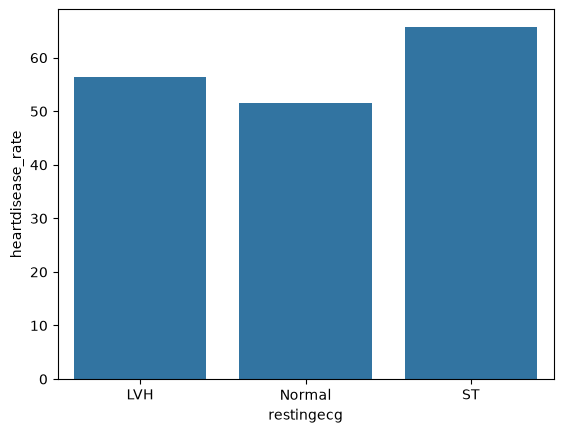

In [31]:
sns.barplot(data=restingecg_df, x='restingecg', y='heartdisease_rate')

In [32]:
df['exerciseangina'].unique()

<ArrowStringArray>
['N', 'Y']
Length: 2, dtype: str

In [33]:
exerciseangina_df = df.groupby(['exerciseangina'])['heartdisease'].mean().mul(100).round(2).reset_index(name='heartdisease_rate')
exerciseangina_df

,exerciseangina,heartdisease_rate
0,N,35.10
1,Y,85.18


<Axes: xlabel='exerciseangina', ylabel='heartdisease_rate'>

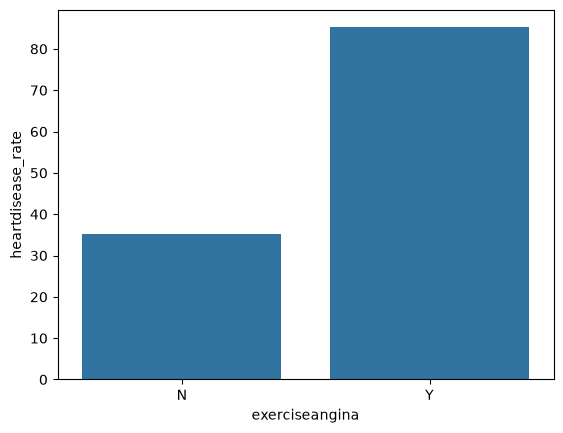

In [34]:
sns.barplot(data=exerciseangina_df, x='exerciseangina', y='heartdisease_rate')

```Observation: Those who has exerciseAngine, are in higher risk of having heartdisease```

In [35]:
df['st_slope'].unique()

<ArrowStringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str

In [36]:
st_slope_df = df.groupby('st_slope')['heartdisease'].mean().mul(100).round(2).reset_index(name='heartdisease_rate')
st_slope_df

,st_slope,heartdisease_rate
0,Down,77.78
1,Flat,82.83
2,Up,19.75


<Axes: xlabel='st_slope', ylabel='heartdisease_rate'>

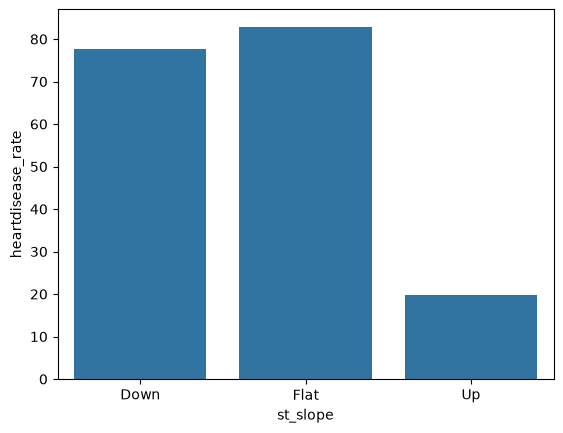

In [37]:
sns.barplot(data=st_slope_df, x='st_slope', y='heartdisease_rate')

```Observation: ST-Slope(UP) -> Lower risk of heartdisease```

<Axes: >

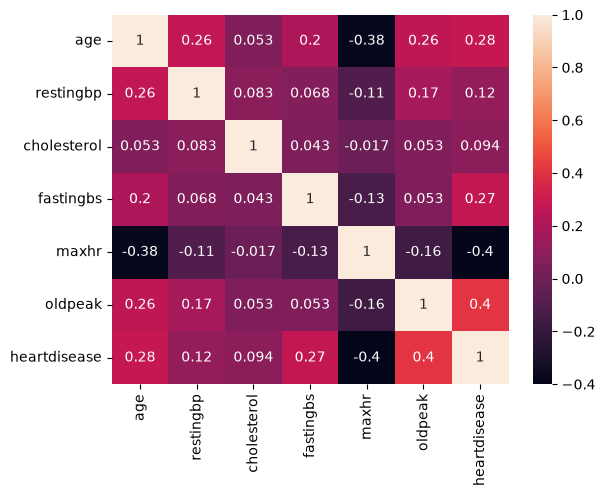

In [38]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

### Converting Categorical column to Numerical Column 

In [39]:
df.head()

,age,sex,chestpaintype,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease,age_group
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,30-40
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,40-50
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,30-40
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,40-50
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,50-60


In [40]:
df['sex'] = df['sex'].map({'M':1, 'F':0})

In [41]:
df['exerciseangina'] = df['exerciseangina'].map({'Y':1, 'N':0})

In [42]:
df = df.rename(columns={
    'sex':'is_male',
    'exerciseangina':'has_exerciseangina'
})

In [43]:
df

,age,is_male,chestpaintype,restingbp,cholesterol,fastingbs,restingecg,maxhr,has_exerciseangina,oldpeak,st_slope,heartdisease,age_group
0,40,1,ATA,140.0,289.0,0,Normal,172,0,0.0,Up,0,30-40
1,49,0,NAP,160.0,180.0,0,Normal,156,0,1.0,Flat,1,40-50
2,37,1,ATA,130.0,283.0,0,ST,98,0,0.0,Up,0,30-40
3,48,0,ASY,138.0,214.0,0,Normal,108,1,1.5,Flat,1,40-50
4,54,1,NAP,150.0,195.0,0,Normal,122,0,0.0,Up,0,50-60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,TA,110.0,264.0,0,Normal,132,0,1.2,Flat,1,40-50
914,68,1,ASY,144.0,193.0,1,Normal,141,0,3.4,Flat,1,60-70
915,57,1,ASY,130.0,131.0,0,Normal,115,1,1.2,Flat,1,50-60
916,57,0,ATA,130.0,236.0,0,LVH,174,0,0.0,Flat,1,50-60


In [44]:
df = pd.get_dummies(df, columns=['chestpaintype', 'restingecg', 'st_slope', 'age_group'])

In [45]:
df = df.astype(int)
df.head()

,age,is_male,restingbp,cholesterol,fastingbs,maxhr,has_exerciseangina,oldpeak,heartdisease,chestpaintype_ASY,...,restingecg_ST,st_slope_Down,st_slope_Flat,st_slope_Up,age_group_20-30,age_group_30-40,age_group_40-50,age_group_50-60,age_group_60-70,age_group_70-80
0,40,1,140,289,0,172,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
1,49,0,160,180,0,156,0,1,1,0,...,0,0,1,0,0,0,1,0,0,0
2,37,1,130,283,0,98,0,0,0,0,...,1,0,0,1,0,1,0,0,0,0
3,48,0,138,214,0,108,1,1,1,1,...,0,0,1,0,0,0,1,0,0,0
4,54,1,150,195,0,122,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0


# Standard Scaling

In [46]:
scale = ss()

df[num_cols] = scale.fit_transform(df[num_cols])

In [47]:
df.sample(10)

,age,is_male,restingbp,cholesterol,fastingbs,maxhr,has_exerciseangina,oldpeak,heartdisease,chestpaintype_ASY,...,restingecg_ST,st_slope_Down,st_slope_Flat,st_slope_Up,age_group_20-30,age_group_30-40,age_group_40-50,age_group_50-60,age_group_60-70,age_group_70-80
552,1.855120,1,0.637353,-0.441294,0,-1.132156,1,0.282891,1,0,...,0,0,1,0,0,0,0,0,0,1
454,0.476173,1,0.192418,-0.779071,1,-0.542683,1,0.282891,1,1,...,0,0,1,0,0,0,0,1,0,0
557,0.264027,1,0.248035,-0.685244,1,-0.581981,1,0.282891,1,0,...,1,0,1,0,0,0,0,1,0,0
598,0.157954,1,-0.697453,-0.347467,0,-0.385490,1,0.282891,1,1,...,0,1,0,0,0,0,0,1,0,0
711,1.324756,1,-0.697453,1.078704,0,0.557666,0,-0.727592,0,1,...,0,0,1,0,0,0,0,0,1,0
113,-1.645286,1,0.414885,0.984877,0,0.518368,0,-0.727592,0,0,...,0,0,0,1,0,1,0,0,0,0
770,-0.796702,0,-1.531707,-0.760305,0,1.382928,0,-0.727592,0,0,...,0,0,0,1,0,0,1,0,0,0
786,1.642975,1,0.414885,0.177965,0,0.361175,0,1.293375,1,0,...,0,0,1,0,0,0,0,0,1,0
61,-1.114921,0,0.971054,0.177965,0,1.500823,0,-0.727592,0,0,...,0,0,0,1,0,0,1,0,0,0
688,2.385485,0,0.414885,-0.891663,0,-0.817771,0,0.282891,0,0,...,1,0,1,0,0,0,0,0,0,1


In [54]:
correlation = {}
features = [col for col in df.columns if col != 'heartdisease']
for feature in features:
    correlation[feature] = prs(df[feature], df['heartdisease'])[0]

df_corr = pd.DataFrame(
    correlation.items(),
    columns=['feature', 'pearson_correlation']
).sort_values(
    by=['pearson_correlation'],
    ascending=False
).reset_index(drop=True)

df_corr

,feature,pearson_correlation
0,st_slope_Flat,0.554134
1,chestpaintype_ASY,0.516716
2,has_exerciseangina,0.494282
3,oldpeak,0.392385
4,is_male,0.305445
5,age,0.282039
6,fastingbs,0.267291
7,age_group_60-70,0.192060
8,st_slope_Down,0.122527
9,restingbp,0.117909
